In [ ]:
import os
from dotenv import load_dotenv
from langchain_community.chat_models import ChatTongyi
from langmem.graphs.prompts import OutputState

load_dotenv()

# 创建大语言模型实例
llm = ChatTongyi(
    model="qwen-plus",
    temperature=0.5,
    api_key=os.environ.get("DASHSCOPE_API_KEY"),
    # streaming=True,
)

In [2]:
from typing import TypedDict
from langgraph.constants import END, START
from langgraph.graph import StateGraph

class InputState(TypedDict):
    user_input: str

class OutputState(TypedDict):
    graph_output: str

class OverallState(TypedDict):
    foo: str
    user_input: str
    graph_output: str

class PrivateState(TypedDict):
    bar: str

def node_1(state: InputState) -> OverallState:
    # Write to OverallState
    return {"foo": state["user_input"] + ">学院"}

def node_2(state: OverallState) -> PrivateState:
    # Read from OverallState, write to PrivateState
    return {"bar": state["foo"] + ">非常"}

def node_3(state: PrivateState) -> OutputState:
    # Read from PrivateState, write to OutputState
    return {"graph_output": state["bar"] + ">靠谱"}

# 构建图
builder = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)

# 添加节点
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

# 添加边
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)

# 编译图
graph = builder.compile()

# 调用图
graph.invoke({"user_input": "你好"})

{'graph_output': '你好>学院>非常>靠谱'}

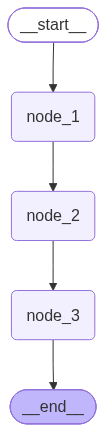

In [3]:
from IPython.display import Image, display
# draw_mermaid方法可以打印出Graph的Mermaid代码
display(Image(graph.get_graph().draw_mermaid_png()))

state案例

In [6]:
from langchain_core.messages import AnyMessage, AIMessage
from langgraph.graph import StateGraph
from langgraph.graph.message import add_messages
from typing import Annotated, TypedDict
from operator import add

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    list_field: Annotated[list[int], add]
    extra_field: int

def node1(state: State):
    new_message = AIMessage(content="你好")
    return {"messages": [new_message], "list_field": [10], "extra_field": 10}

def node2(state: State):
    new_message = AIMessage(content="LangGraph")
    return {"messages": [new_message], "list_field": [20], "extra_field": 20}

graph = (StateGraph(State)
         .add_node("node1", node1)
         .add_node("node2", node2)
         .set_entry_point("node1")
         .add_edge("node1", "node2")
         .compile()
         )
input_message = {"role": "user", "content": "Hi"}
result = graph.invoke({"messages": [input_message], "list_field": [1, 2, 3]})
print(result)
print("*"*20)
for message in result["messages"]:
    message.pretty_print()
print("*"*20)
print(result.get("extra_field"))

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='393b2267-1bfe-41af-a004-48bcbbaee3b2'), AIMessage(content='你好', additional_kwargs={}, response_metadata={}, id='d6207c36-9bc4-4c5e-8a64-3d45d715e6cb', tool_calls=[], invalid_tool_calls=[]), AIMessage(content='LangGraph', additional_kwargs={}, response_metadata={}, id='48c9d5c3-288f-41f1-a917-3de6de65f103', tool_calls=[], invalid_tool_calls=[])], 'list_field': [1, 2, 3, 10, 20], 'extra_field': 20}
********************
================================ Human Message =================================

Hi
================================== Ai Message ==================================

你好
================================== Ai Message ==================================

LangGraph
********************
20


node案例

In [11]:
import time
from typing import TypedDict
from langchain_core.runnables import RunnableConfig
from langgraph.constants import END, START
from langgraph.graph import StateGraph
from langgraph.types import CachePolicy
from langgraph.cache.memory import InMemoryCache # 是LangGraph中的，而不是LangChain中的

# 配置状态
class State(TypedDict):
    number: int
    user_id: str

# 配置信息
class ConfigSchema(TypedDict):
    user_id: str

def node_1(state: State, config: RunnableConfig):
    time.sleep(3)
    user_id = config["configurable"]["user_id"]
    return {"number": state["number"] + 10, "user_id": user_id}

builder = StateGraph(State, context_schema=ConfigSchema)
# Node缓存5秒
builder.add_node("node_1", node_1, cache_policy=CachePolicy(ttl=5))
builder.add_edge(START, "node_1")
builder.add_edge("node_1", END)

graph = builder.compile(cache=InMemoryCache())
print(graph.invoke({"number": 5}, config={"configurable": {"user_id": "123"}}, stream_mode="updates"))
# node入参相同，就会走缓存，不会重复执行。
# LangGraph 的 CachePolicy 缓存 key = 节点函数的输入参数序列化（即 state），不包含 config。如果需要某个字段影响缓存命中，把它放进 state 而非 config
print(graph.invoke({"number": 5}, config={"configurable": {"user_id": "456"}}, stream_mode="updates"))


[{'node_1': {'number': 15, 'user_id': '123'}}]
[{'node_1': {'number': 15, 'user_id': '123'}, '__metadata__': {'cached': True}}]


Edge边

number is  4
go to END
{'number': 4}
********************
number is  7
go to node_1
{'number': 8}


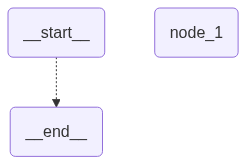

In [5]:
from typing import TypedDict
from langchain_core.runnables import RunnableConfig
from langgraph.constants import END, START
from langgraph.graph import StateGraph

# 配置状态
class State(TypedDict):
    number: int

def node_1(state: State, config: RunnableConfig):
    return {"number": state["number"] + 1}

builder = StateGraph(State)

# 添加节点
builder.add_node("node_1", node_1)

def routing_func(state: State) -> str:
    print("number is ", state["number"])
    if state["number"] > 5:
        print("go to node_1")
        return "node_1"
    else:
        print("go to END")
        return END

builder.add_edge("node_1", END)
builder.add_conditional_edges(START, routing_func)
graph =builder.compile()
print(graph.invoke({"number": 4}))
print("*"*20)
print(graph.invoke({"number": 7}))

# 补充看一下图的结构
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from operator import add

# ========== 1. 定义 State ==========
class State(TypedDict):
    messages: Annotated[list[str], add]
    results: Annotated[list[str], add]

# ========== 2. 定义节点 ==========
def router(state: State) -> list[Send]:
    """
    条件边函数：根据消息内容动态决定发送到哪个节点。
    返回 Send 列表 → 每个 Send 指定【目标节点】+【局部输入】。
    add_conditional_edges 收到这个列表后，会并行调度所有 Send。
    """
    sends = []
    for msg in state["messages"]:
        if msg.startswith("query:"):
            # 查询类消息 → 发送到 search_node
            sends.append(Send("search_node", {"task": msg}))
        elif msg.startswith("calc:"):
            # 计算类消息 → 发送到 math_node
            sends.append(Send("math_node", {"task": msg}))
        # 其他消息被忽略（不生成 Send）
    print(f"[router] 生成了 {len(sends)} 个 Send:")
    for s in sends:
        print(f"         → Send(node={s.node}, input={s.arg})")
    return sends

def search_node(state: dict) -> dict:
    """处理查询任务"""
    task = state["task"]
    result = f"搜索结果: '{task}' 的答案是42"
    print(f"[search_node] 收到: {task} → 返回: {result}")
    return {"results": [result]}

def math_node(state: dict) -> dict:
    """处理计算任务"""
    task = state["task"]
    result = f"计算结果: '{task}' = 3.14"
    print(f"[math_node]   收到: {task} → 返回: {result}")
    return {"results": [result]}

# ========== 3. 构建图 ==========
builder = StateGraph(State)

# 添加节点
builder.add_node("search_node", search_node)
builder.add_node("math_node", math_node)

# ⭐ 核心：add_conditional_edges + Send
# 注意：当 routing_func 返回 Send 列表时，第三个参数(path_map)被忽略
# LangGraph 直接从每个 Send 对象中提取目标节点名
builder.add_conditional_edges(START, router)

# 两个处理节点都连接到 END
builder.add_edge("search_node", END)
builder.add_edge("math_node", END)

graph = builder.compile()

# ========== 4. 运行 ==========

initial_state = {
    "messages": [
        "query:LangGraph是什么",
        "calc:2+2",
        "query:Python版本",
        "ignored:这条会被跳过",
        "calc:圆周率",
    ],
    "results": [],  # 初始空列表，reducer 会追加
}

print("开始执行图")
print("=" * 50)
final = graph.invoke(initial_state)
print("=" * 50)
print(f"最终 results: {final['results']}")

开始执行图
[router] 生成了 4 个 Send:
         → Send(node=search_node, input={'task': 'query:LangGraph是什么'})
         → Send(node=math_node, input={'task': 'calc:2+2'})
         → Send(node=search_node, input={'task': 'query:Python版本'})
         → Send(node=math_node, input={'task': 'calc:圆周率'})
[search_node] 收到: query:LangGraph是什么 → 返回: 搜索结果: 'query:LangGraph是什么' 的答案是42
[search_node] 收到: query:Python版本 → 返回: 搜索结果: 'query:Python版本' 的答案是42
[math_node]   收到: calc:2+2 → 返回: 计算结果: 'calc:2+2' = 3.14
[math_node]   收到: calc:圆周率 → 返回: 计算结果: 'calc:圆周率' = 3.14
最终 results: ["搜索结果: 'query:LangGraph是什么' 的答案是42", "计算结果: 'calc:2+2' = 3.14", "搜索结果: 'query:Python版本' 的答案是42", "计算结果: 'calc:圆周率' = 3.14"]


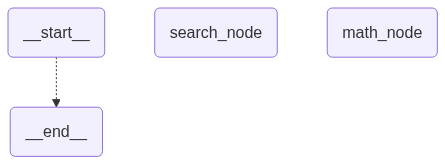

In [9]:
#补充看一下Graph的结构
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
from operator import add
from typing import TypedDict, Annotated

from langgraph.constants import END, START
from langgraph.graph import StateGraph
from langgraph.types import Command

# 配置状态
class State(TypedDict):
    messages: Annotated[list[str], add]

def node_1(state: State):
    new_message = []
    for message in state["messages"]:
        new_message.append(message + "!")
    return Command(
        goto=END,
        update={"messages": new_message},
    )

builder = StateGraph(State)
# 添加节点
builder.add_node("node_1", node_1)

# node_1中通过Command同时集成了更新State状态和指定下一个节点
builder.add_edge(START, "node_1")
graph = builder.compile()
print(graph.invoke({"messages": ["hello", "world", "你好", "LangGraph"]}))

{'messages': ['hello', 'world', '你好', 'LangGraph', 'hello!', 'world!', '你好!', 'LangGraph!']}


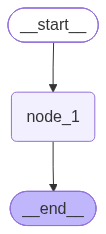

In [12]:
#补充看一下Graph的结构
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

子图

In [1]:
# subgraph与graph使用相同的State
from operator import add
from typing import TypedDict, Annotated
from langgraph.constants import END, START
from langgraph.graph import StateGraph, MessagesState, START

class State(TypedDict):
    messages: Annotated[list[str], add]

def sub_node_1(state: State) -> MessagesState:
    return {"messages": ["response from sub graph"]}

subgraph_builder = StateGraph(State)

subgraph_builder.add_node("sub_node_1", sub_node_1)

subgraph_builder.add_edge(START, "sub_node_1")
subgraph_builder.add_edge("sub_node_1", END)

subgraph = subgraph_builder.compile()

# Parent graph
builder = StateGraph(State)

builder.add_node("subgraph_node", subgraph)

builder.add_edge(START, "subgraph_node")
builder.add_edge("subgraph_node", END)

graph = builder.compile()

print(graph.invoke({"messages":["hello subgraph"]}))
# 结果hello subgraph会出现两次，这是应为在subgraph_node中默认调用了一次subgraph.invoke(state)
# 方法。主图也会调用一次subgraph.invoke(state)方法。这就会往state中添加两次语句。
# 要想规避这种情况，可以给助graph和子graph定义不同的State

{'messages': ['hello subgraph', 'hello subgraph', 'response from sub graph']}


In [8]:
for chunk in graph.stream({"messages":["hello 你好"]}, stream_mode="debug"):
    print(chunk)

{'step': 1, 'timestamp': '2026-09-24T03:54:06.474467+00:00', 'type': 'task', 'payload': {'id': '760d5aa7-6185-1f69-941f-b3c06355d83e', 'name': 'subgraph_node', 'input': {'messages': ['hello 你好']}, 'triggers': ('branch:to:subgraph_node',)}}
{'step': 1, 'timestamp': '2026-09-24T03:54:06.475338+00:00', 'type': 'task_result', 'payload': {'id': '760d5aa7-6185-1f69-941f-b3c06355d83e', 'name': 'subgraph_node', 'error': None, 'result': {'messages': ['hello 你好', 'response from sub graph']}, 'interrupts': []}}


In [9]:
from typing import TypedDict
from langgraph.graph import StateGraph, START
from langgraph.config import get_stream_writer

class State(TypedDict):
    query: str
    answer: str

def node(state: State):
    writer = get_stream_writer()
    writer({"自定义key": "在节点内返回自定义信息"})
    return {"answer": "some answer"}

graph = (
    StateGraph(State)
    .add_node(node)
    .add_edge(START, "node")
    .compile()
)

inputs = {"query": "你好"}

# Usage
for chunk in graph.stream(inputs, stream_mode="custom"):
    print(chunk)

{'自定义key': '在节点内返回自定义信息'}
